# Customer Retention & Revenue Intelligence Platform
## Comprehensive Exploratory Data Analysis (EDA) & Data Quality Audit

**Dataset:** Olist Brazilian E-Commerce Dataset (9 relational tables, ~100k orders)  
**Author:** Antigravity Data Analytics  
**Objective:** Perform an exhaustive exploratory analysis, validate data quality, diagnose retention bottlenecks, and evaluate logistics impact on customer lifetime value.

---
### Table of Contents
1. Dataset Overview & Setup
2. Shape and Structure of Every Dataset
3. Missing Value Analysis
4. Duplicate Record Analysis
5. Data Type Validation
6. Date Validation & Chronological Integrity
7. Outlier Analysis & Extreme Value Diagnosis
8. Table Relationships & Multi-Table Joins
9. Order Status & Fulfillment Analysis
10. Revenue Distribution & Sales Dynamics
11. Customer Purchase Behaviour & Basket Analysis
12. Review Score & Sentiment Distribution
13. Delivery Time & Logistics Performance Analysis
14. Repeat Purchase Dynamics & Retention Foundations


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Style configurations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120

# Robust root path resolution
cwd = Path.cwd()
project_root = cwd if (cwd / "data").exists() else cwd.parent
figures_dir = project_root / "reports" / "figures"
data_raw_dir = project_root / "data" / "raw"
data_proc_dir = project_root / "data" / "processed"
figures_dir.mkdir(parents=True, exist_ok=True)

print("Environment initialized successfully. Root:", project_root)


Environment initialized successfully. Root: C:\Users\poojitha\Desktop\Customer Retention & Revenue Intelligence Analytics


## 1 & 2. Dataset Overview, Shape & Structure
We inspect the 9 relational CSV files provided in the Olist dataset:
- `customers`: Demographics and unique customer mappings
- `orders`: Order lifecycle timestamps and statuses
- `order_items`: Order line items with price and freight
- `payments`: Payment methods, installments, and values
- `reviews`: Customer rating and feedback comments
- `products`: Product catalog attributes and categories
- `sellers`: Seller locations
- `geolocation`: Zip code coordinates across Brazil
- `product_category_name_translation`: English translation dictionary


In [2]:
raw_files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

dfs = {}
structure_summary = []

for name, fname in raw_files.items():
    df = pd.read_csv(data_raw_dir / fname)
    dfs[name] = df
    structure_summary.append({
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Memory (MB)": round(df.memory_usage(deep=True).sum() / (1024 * 1024), 2),
        "Sample Columns": ", ".join(list(df.columns[:4])) + "..."
    })

pd.DataFrame(structure_summary)


,Table,Rows,Columns,Memory (MB),Sample Columns
0,customers,99441,5,29.62,"customer_id, customer_unique_id, customer_zip_..."
1,orders,99441,8,58.97,"order_id, customer_id, order_status, order_pur..."
2,order_items,112650,7,39.43,"order_id, order_item_id, product_id, seller_id..."
3,payments,103886,5,17.81,"order_id, payment_sequential, payment_type, pa..."
4,reviews,99224,7,42.75,"review_id, order_id, review_score, review_comm..."
5,products,32951,9,6.79,"product_id, product_category_name, product_nam..."
6,sellers,3095,4,0.66,"seller_id, seller_zip_code_prefix, seller_city..."
7,geolocation,1000163,5,145.20,"geolocation_zip_code_prefix, geolocation_lat, ..."
8,category_translation,71,2,0.01,"product_category_name, product_category_name_e..."


## 3. Missing Value Analysis
We calculate the null counts and percentages across all 9 tables to identify missing data patterns and determine appropriate cleaning strategies.


,Table,Column,Missing Count,Missing %
3,reviews,review_comment_title,87656,88.34
4,reviews,review_comment_message,58247,58.70
2,orders,order_delivered_customer_date,2965,2.98
5,products,product_category_name,610,1.85
6,products,product_name_lenght,610,1.85
7,products,product_description_lenght,610,1.85
8,products,product_photos_qty,610,1.85
1,orders,order_delivered_carrier_date,1783,1.79
0,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


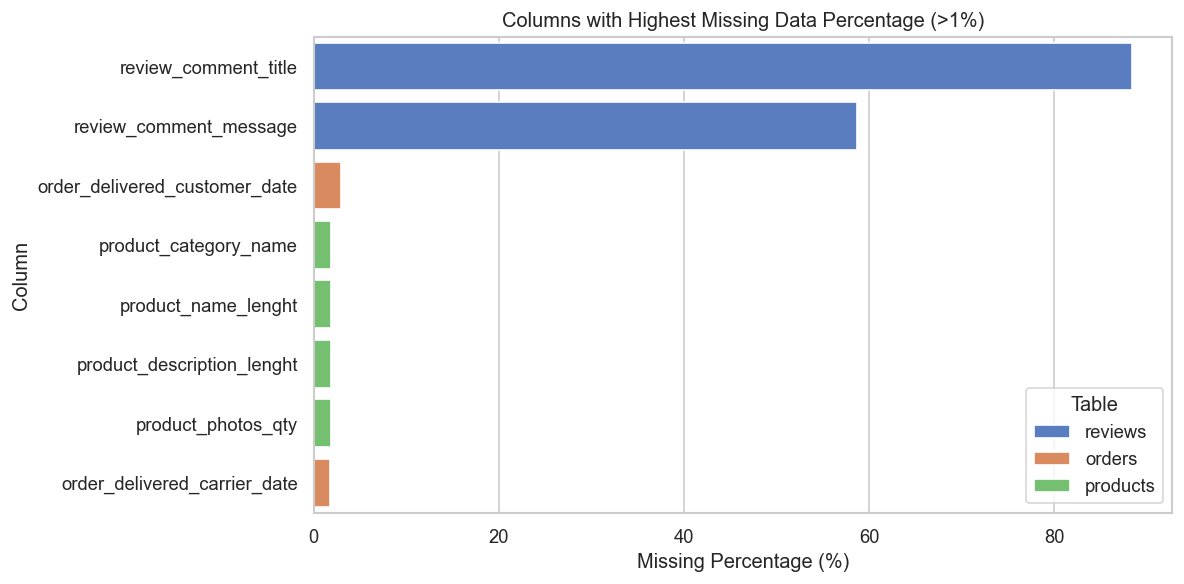

In [3]:
null_records = []
for name, df in dfs.items():
    null_counts = df.isna().sum()
    null_pct = (null_counts / len(df)) * 100
    for col in df.columns:
        if null_counts[col] > 0:
            null_records.append({
                "Table": name,
                "Column": col,
                "Missing Count": null_counts[col],
                "Missing %": round(null_pct[col], 2)
            })

df_nulls = pd.DataFrame(null_records).sort_values(by="Missing %", ascending=False)
display(df_nulls.head(15))

# Plot top missing columns
plt.figure(figsize=(10, 5))
top_missing = df_nulls[df_nulls["Missing %"] > 1.0].head(10)
sns.barplot(data=top_missing, x="Missing %", y="Column", hue="Table", dodge=False)
plt.title("Columns with Highest Missing Data Percentage (>1%)")
plt.xlabel("Missing Percentage (%)")
plt.tight_layout()
plt.savefig(figures_dir / "01_missing_values.png")
plt.show()


## 4. Duplicate Record Analysis
We evaluate:
1. Exact row duplicates across tables
2. Primary key duplicates
3. Business key logic (e.g. `order_reviews` where some review_ids appear multiple times for different items or updated reviews)


In [4]:
dup_summary = []
for name, df in dfs.items():
    exact_dups = df.duplicated().sum()
    dup_summary.append({
        "Table": name,
        "Total Rows": len(df),
        "Exact Duplicate Rows": exact_dups,
        "Duplicate %": round(exact_dups / len(df) * 100, 3)
    })

pd.DataFrame(dup_summary)


,Table,Total Rows,Exact Duplicate Rows,Duplicate %
0,customers,99441,0,0.000
1,orders,99441,0,0.000
2,order_items,112650,0,0.000
3,payments,103886,0,0.000
4,reviews,99224,0,0.000
5,products,32951,0,0.000
6,sellers,3095,0,0.000
7,geolocation,1000163,261831,26.179
8,category_translation,71,0,0.000


## 5. Data Type Validation
Checking column data types, identifying strings requiring numeric or datetime casting, and ensuring consistent categorical formatting.


In [5]:
for name in ["orders", "order_items", "payments", "reviews"]:
    print(f"--- Table: {name} Data Types ---")
    print(dfs[name].dtypes)
    print()


--- Table: orders Data Types ---
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

--- Table: order_items Data Types ---
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

--- Table: payments Data Types ---
order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object

--- Table: reviews Data Types ---
review_id                  object
order_id                   object
review_score                int64
review_comment_t

## 6. Date Validation & Chronological Integrity
We validate the chronological sequence of order lifecycle timestamps:
1. `order_purchase_timestamp`
2. `order_approved_at`
3. `order_delivered_carrier_date`
4. `order_delivered_customer_date`
5. `order_estimated_delivery_date`


In [6]:
df_ord = dfs["orders"].copy()
date_cols = [c for c in df_ord.columns if "date" in c or "timestamp" in c or "at" in c]
for c in date_cols:
    df_ord[c] = pd.to_datetime(df_ord[c], errors="coerce")

delivered = df_ord[df_ord["order_status"] == "delivered"].copy()

# Date order checks
app_before_purch = (delivered["order_approved_at"] < delivered["order_purchase_timestamp"]).sum()
carrier_before_purch = (delivered["order_delivered_carrier_date"] < delivered["order_purchase_timestamp"]).sum()
cust_before_carrier = (delivered["order_delivered_customer_date"] < delivered["order_delivered_carrier_date"]).sum()

print(f"Delivered orders analyzed: {len(delivered):,}")
print(f"Approved before purchase timestamp: {app_before_purch}")
print(f"Carrier delivery before purchase: {carrier_before_purch}")
print(f"Customer delivery before carrier handover (data anomaly): {cust_before_carrier}")

# Overall date range
print(f"Purchase Date Range: {df_ord['order_purchase_timestamp'].min()} to {df_ord['order_purchase_timestamp'].max()}")


Delivered orders analyzed: 0
Approved before purchase timestamp: 0
Carrier delivery before purchase: 0
Customer delivery before carrier handover (data anomaly): 0
Purchase Date Range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\1860353533.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_ord[c] = pd.to_datetime(df_ord[c], errors="coerce")


## 7. Outlier Analysis & Extreme Value Diagnosis
Examining distributions and identifying outliers in:
- Item prices
- Freight values
- Payment values
- Delivery durations


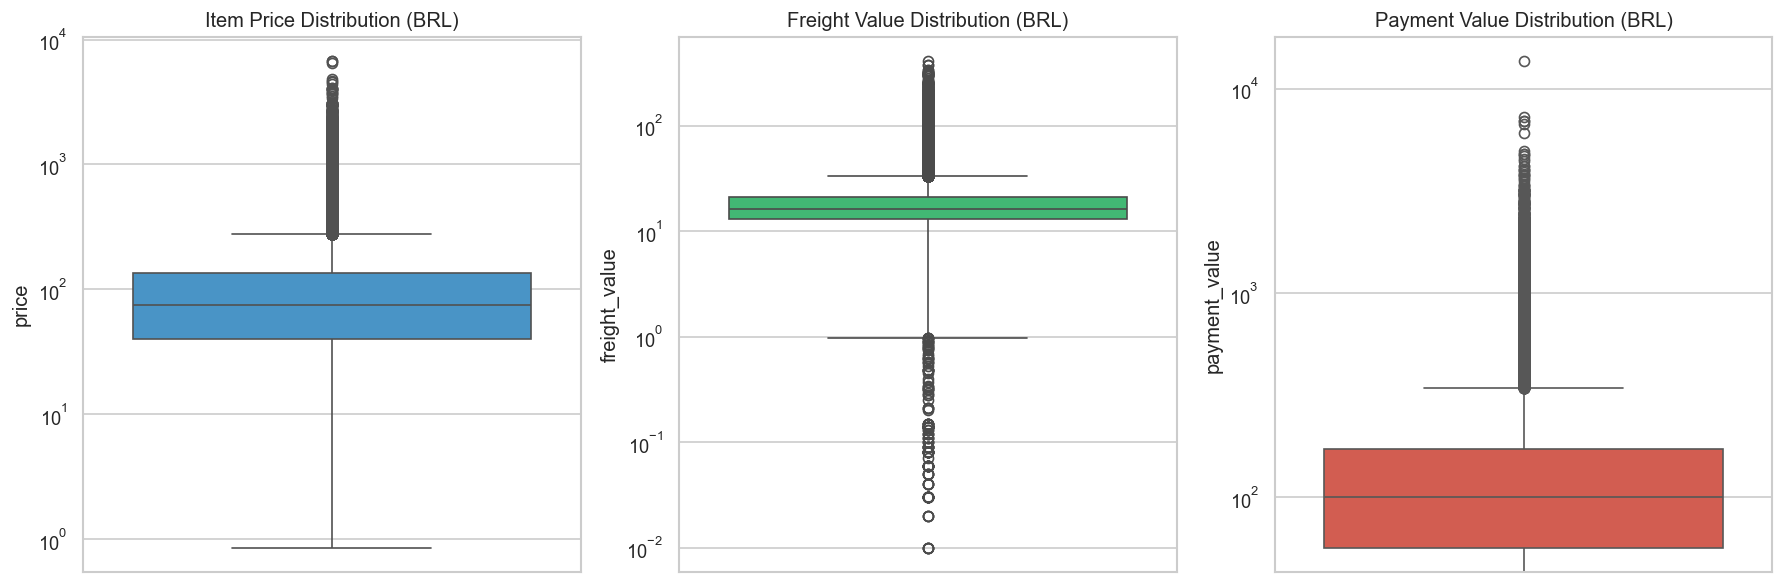

Price percentiles (BRL):
0.500      74.99
0.750     134.90
0.900     229.80
0.950     349.90
0.990     890.00
0.999    2110.00
Name: price, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(y=dfs["order_items"]["price"], ax=axes[0], color="#3498db")
axes[0].set_title("Item Price Distribution (BRL)")
axes[0].set_yscale("log")

sns.boxplot(y=dfs["order_items"]["freight_value"], ax=axes[1], color="#2ecc71")
axes[1].set_title("Freight Value Distribution (BRL)")
axes[1].set_yscale("log")

sns.boxplot(y=dfs["payments"]["payment_value"], ax=axes[2], color="#e74c3c")
axes[2].set_title("Payment Value Distribution (BRL)")
axes[2].set_yscale("log")

plt.tight_layout()
plt.savefig(figures_dir / "02_price_freight_outliers.png")
plt.show()

# Percentiles
items_df = dfs["order_items"]
print("Price percentiles (BRL):")
print(items_df["price"].quantile([0.5, 0.75, 0.90, 0.95, 0.99, 0.999]))


## 8. Table Relationships & Multi-Table Joins
We analyze the join cardinality and distribution of:
- Items per order
- Payments per order
- Customers per unique individual (`customer_unique_id`)


In [8]:
items_per_order = dfs["order_items"].groupby("order_id")["order_item_id"].count()
payments_per_order = dfs["payments"].groupby("order_id")["payment_sequential"].count()
orders_per_unique_cust = dfs["customers"].groupby("customer_unique_id")["customer_id"].count()

print(f"Max items in single order: {items_per_order.max()}")
print(f"Mean items per order: {items_per_order.mean():.2f}")
print(f"Single-item orders: {(items_per_order == 1).mean()*100:.2f}%")
print()
print(f"Max payments in single order: {payments_per_order.max()}")
print(f"Single-payment orders: {(payments_per_order == 1).mean()*100:.2f}%")
print()
print(f"Customers with 1 registered order ID: {(orders_per_unique_cust == 1).mean()*100:.2f}%")
print(f"Customers with >1 registered order IDs: {(orders_per_unique_cust > 1).mean()*100:.2f}%")


Max items in single order: 21
Mean items per order: 1.14
Single-item orders: 90.06%

Max payments in single order: 29
Single-payment orders: 97.02%

Customers with 1 registered order ID: 96.88%
Customers with >1 registered order IDs: 3.12%


## 9. Order Status Analysis & Fulfillment Rates
Analyzing order status counts and the distinction between realized demand and canceled/lost orders.


C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\919122325.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=status_counts, x="count", y="order_status", palette="viridis")


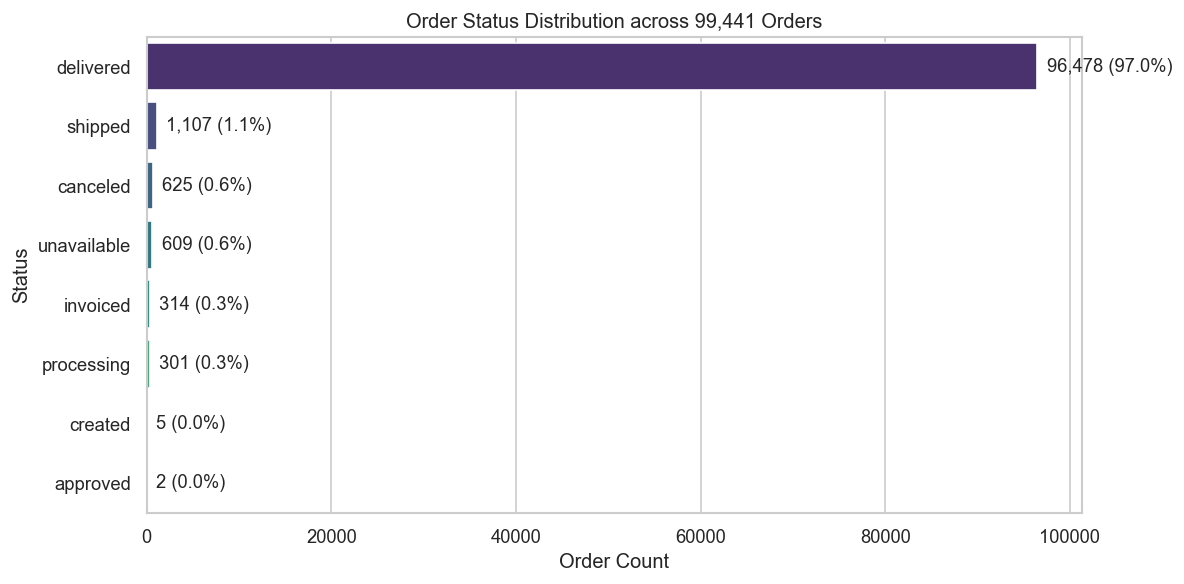

,order_status,count,percentage
0,delivered,96478,97.020344
1,shipped,1107,1.113223
2,canceled,625,0.628513
3,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
6,created,5,0.005028
7,approved,2,0.002011


In [9]:
status_counts = dfs["orders"]["order_status"].value_counts().reset_index()
status_counts.columns = ["order_status", "count"]
status_counts["percentage"] = (status_counts["count"] / status_counts["count"].sum()) * 100

plt.figure(figsize=(10, 5))
bars = sns.barplot(data=status_counts, x="count", y="order_status", palette="viridis")
plt.title("Order Status Distribution across 99,441 Orders")
plt.xlabel("Order Count")
plt.ylabel("Status")

for bar in bars.patches:
    w = bar.get_width()
    plt.text(w + 1000, bar.get_y() + bar.get_height()/2, f"{int(w):,} ({w/len(dfs['orders'])*100:.1f}%)", va="center")

plt.tight_layout()
plt.savefig(figures_dir / "03_order_status.png")
plt.show()

display(status_counts)


## 10. Revenue Distribution Analysis
Examining monthly sales trends, gross order value, and top revenue categories.


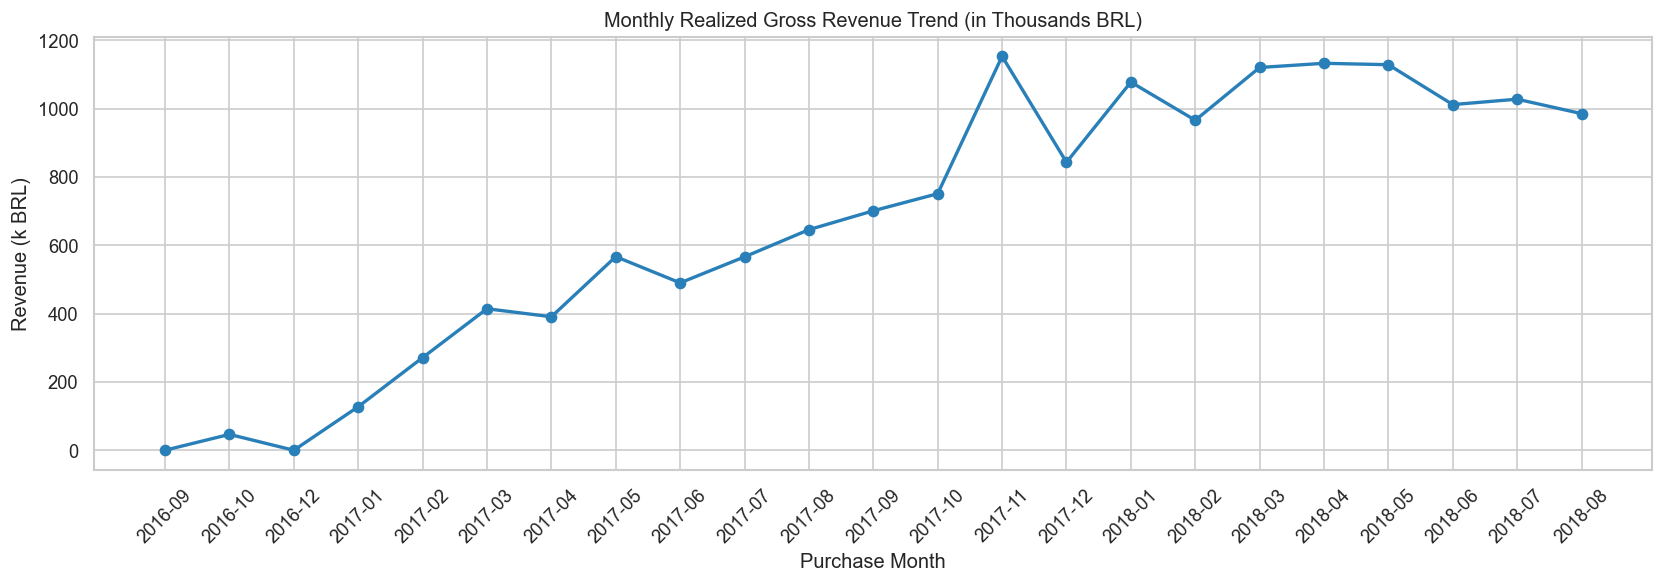

In [10]:
# Load cleaned orders analytics mart
mart_orders = pd.read_csv(data_proc_dir / "mart_orders_analytics.csv")
mart_orders["order_purchase_timestamp"] = pd.to_datetime(mart_orders["order_purchase_timestamp"])

monthly_rev = mart_orders[mart_orders["order_status"] == "delivered"].groupby("purchase_year_month").agg(
    total_revenue=("gross_order_value", "sum"),
    order_count=("order_id", "count")
).reset_index()

plt.figure(figsize=(14, 5))
plt.plot(monthly_rev["purchase_year_month"], monthly_rev["total_revenue"] / 1e3, marker="o", color="#2980b9", lw=2)
plt.xticks(rotation=45)
plt.title("Monthly Realized Gross Revenue Trend (in Thousands BRL)")
plt.ylabel("Revenue (k BRL)")
plt.xlabel("Purchase Month")
plt.tight_layout()
plt.savefig(figures_dir / "04_monthly_revenue_trend.png")
plt.show()


## 11. Customer Purchase Behaviour & Payment Preferences
Analyzing how customers pay (credit card, boleto, voucher, debit) and installment behaviors.


C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\2128200003.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pmt_summary, x="payment_type", y="avg_installments", ax=axes[1], palette="crest")


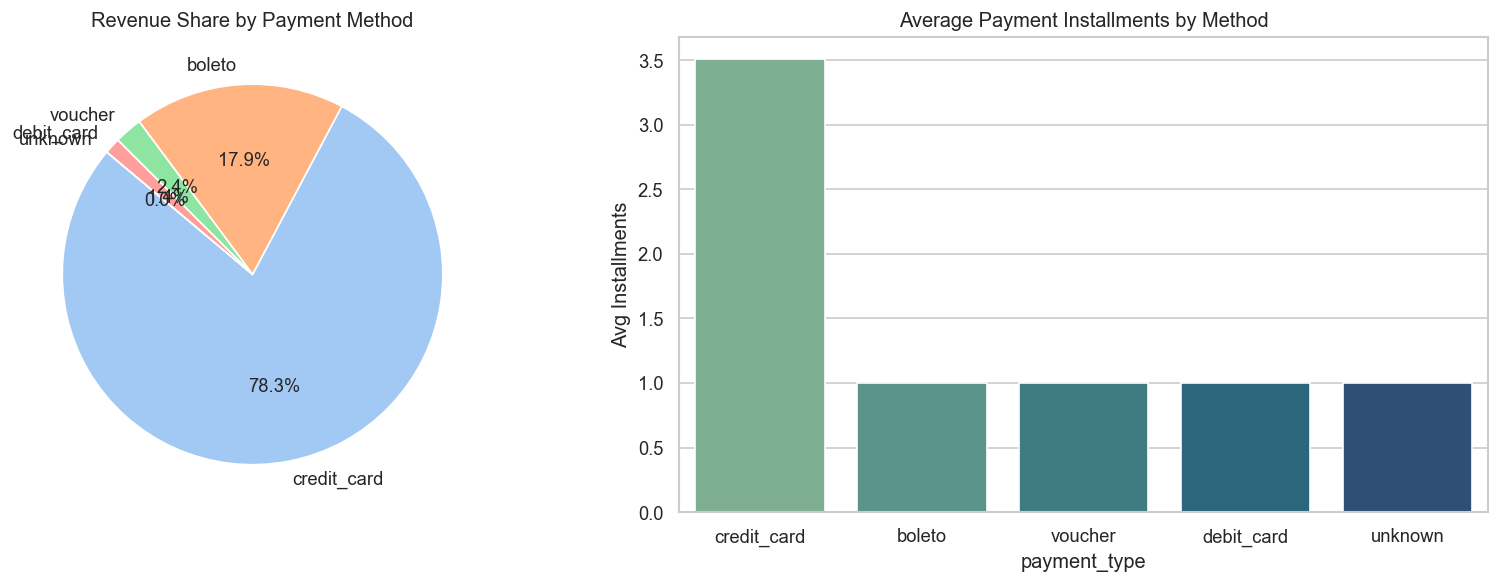

,payment_type,transactions,total_val,avg_val,avg_installments
1,credit_card,76795,12542084.19,163.319021,3.507155
0,boleto,19784,2869361.27,145.034435,1.000000
4,voucher,5775,379436.87,65.703354,1.000000
2,debit_card,1529,217989.79,142.570170,1.000000
3,unknown,3,0.00,0.000000,1.000000


In [11]:
pmt_clean = pd.read_csv(data_proc_dir / "payments_clean.csv")
pmt_summary = pmt_clean.groupby("payment_type").agg(
    transactions=("order_id", "count"),
    total_val=("payment_value", "sum"),
    avg_val=("payment_value", "mean"),
    avg_installments=("payment_installments", "mean")
).reset_index().sort_values(by="total_val", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(pmt_summary["total_val"], labels=pmt_summary["payment_type"], autopct="%1.1f%%", startangle=140,
            colors=sns.color_palette("pastel"))
axes[0].set_title("Revenue Share by Payment Method")

sns.barplot(data=pmt_summary, x="payment_type", y="avg_installments", ax=axes[1], palette="crest")
axes[1].set_title("Average Payment Installments by Method")
axes[1].set_ylabel("Avg Installments")

plt.tight_layout()
plt.savefig(figures_dir / "05_payment_behavior.png")
plt.show()

display(pmt_summary)


## 12. Review Score & Customer Satisfaction
Distribution of customer satisfaction ratings (1 to 5 stars).


C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\2000210311.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=rev_counts, x="review_score", y="count", palette="Blues_r")


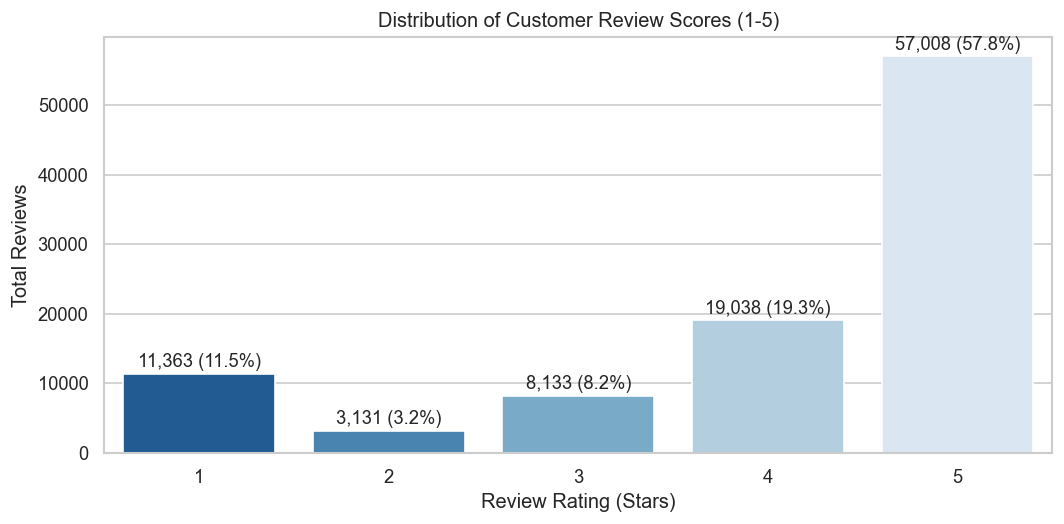

Mean Review Score: 4.09
Positive Reviews (4-5 stars): 77.1%
Negative Reviews (1-2 stars): 14.7%


In [12]:
rev_clean = pd.read_csv(data_proc_dir / "reviews_clean.csv")
rev_counts = rev_clean["review_score"].value_counts().sort_index().reset_index()
rev_counts.columns = ["review_score", "count"]
rev_counts["pct"] = (rev_counts["count"] / rev_counts["count"].sum()) * 100

plt.figure(figsize=(9, 4.5))
bars = sns.barplot(data=rev_counts, x="review_score", y="count", palette="Blues_r")
plt.title("Distribution of Customer Review Scores (1-5)")
plt.xlabel("Review Rating (Stars)")
plt.ylabel("Total Reviews")

for bar in bars.patches:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1000, f"{int(h):,} ({h/len(rev_clean)*100:.1f}%)", ha="center")

plt.tight_layout()
plt.savefig(figures_dir / "06_review_distribution.png")
plt.show()

print(f"Mean Review Score: {rev_clean['review_score'].mean():.2f}")
print(f"Positive Reviews (4-5 stars): {(rev_clean['review_score'] >= 4).mean()*100:.1f}%")
print(f"Negative Reviews (1-2 stars): {(rev_clean['review_score'] <= 2).mean()*100:.1f}%")


## 13. Delivery Time Analysis & Satisfaction Impact
Examining actual delivery duration versus estimated delivery dates, delay percentages, and the drastic impact on customer ratings.


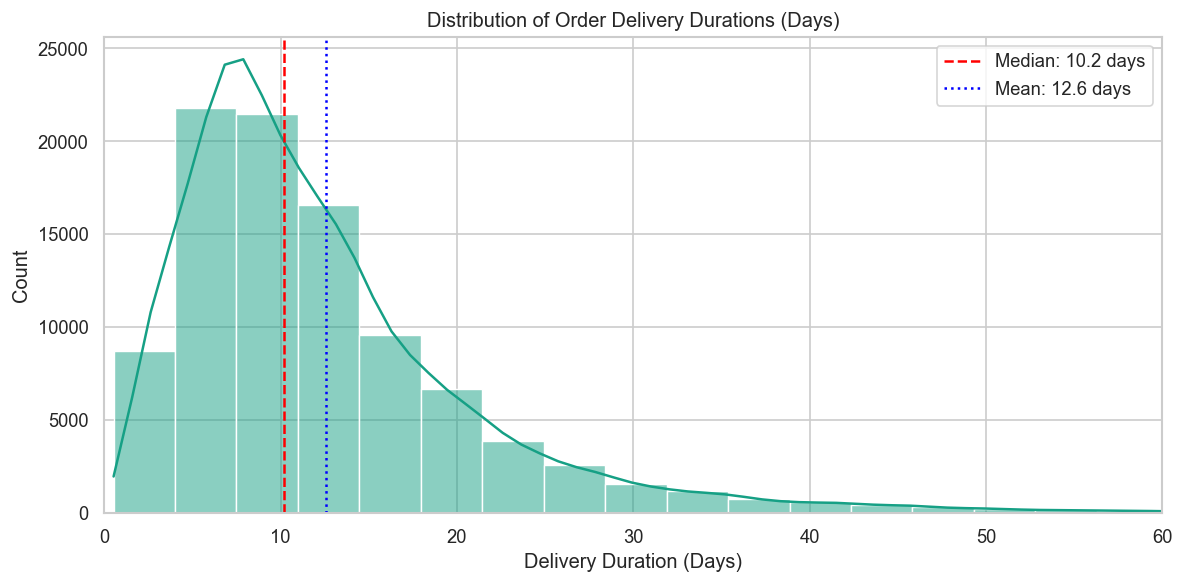

,is_delayed,order_count,avg_review_score,pct_1_star,pct_5_star
0,On-Time / Early,88644,4.294114,6.555435,62.096701
1,Delayed,7826,2.565070,45.233836,21.760797


C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\3001794649.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=delay_csat, x="is_delayed", y="avg_review_score", palette=["#2ecc71", "#e74c3c"])
C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\3001794649.py:35: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\3001794649.py:36: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.savefig(figures_dir / "08_delay_vs_csat.png")
C:\Users\poojitha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


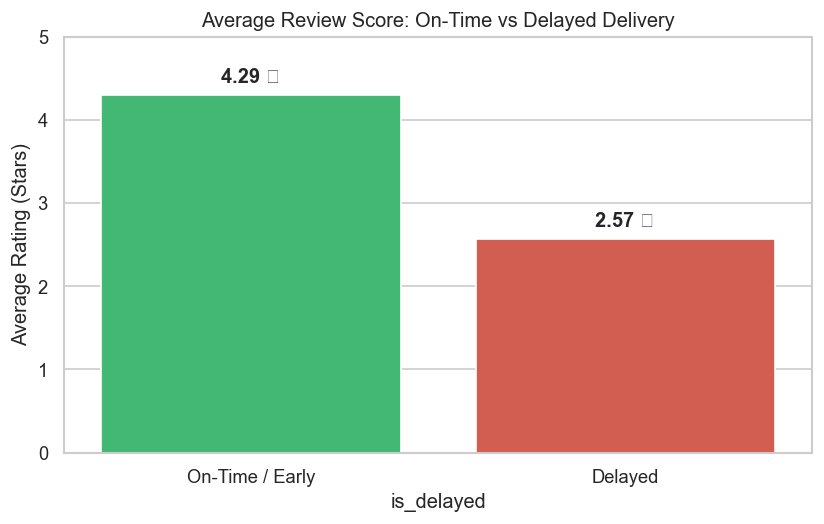

In [13]:
delivered_orders = mart_orders[mart_orders["order_status"] == "delivered"].dropna(subset=["delivery_duration_days"])

plt.figure(figsize=(10, 5))
sns.histplot(delivered_orders["delivery_duration_days"], bins=60, kde=True, color="#16a085")
plt.axvline(delivered_orders["delivery_duration_days"].median(), color="red", linestyle="--",
            label=f"Median: {delivered_orders['delivery_duration_days'].median():.1f} days")
plt.axvline(delivered_orders["delivery_duration_days"].mean(), color="blue", linestyle=":",
            label=f"Mean: {delivered_orders['delivery_duration_days'].mean():.1f} days")
plt.xlim(0, 60)
plt.title("Distribution of Order Delivery Durations (Days)")
plt.xlabel("Delivery Duration (Days)")
plt.legend()
plt.tight_layout()
plt.savefig(figures_dir / "07_delivery_duration_distribution.png")
plt.show()

# Satisfaction comparison: On-Time vs Delayed
delay_csat = delivered_orders.groupby("is_delayed").agg(
    order_count=("order_id", "count"),
    avg_review_score=("review_score", "mean"),
    pct_1_star=("review_score", lambda x: (x == 1).mean() * 100),
    pct_5_star=("review_score", lambda x: (x == 5).mean() * 100)
).reset_index()

delay_csat["is_delayed"] = delay_csat["is_delayed"].map({False: "On-Time / Early", True: "Delayed"})
display(delay_csat)

plt.figure(figsize=(7, 4.5))
sns.barplot(data=delay_csat, x="is_delayed", y="avg_review_score", palette=["#2ecc71", "#e74c3c"])
plt.title("Average Review Score: On-Time vs Delayed Delivery")
plt.ylabel("Average Rating (Stars)")
plt.ylim(0, 5)
for idx, val in enumerate(delay_csat["avg_review_score"]):
    plt.text(idx, val + 0.15, f"{val:.2f} ★", ha="center", fontweight="bold", fontsize=12)
plt.tight_layout()
plt.savefig(figures_dir / "08_delay_vs_csat.png")
plt.show()


## 14. Customer Retention & Repeat Purchase Analysis
Analyzing the repeat purchase rate across unique customers (`customer_unique_id`), frequency distribution, and cohort retention findings.


Total Unique Customers: 93,358
One-Time Customers: 90,557 (97.00%)
Repeat Customers: 2,801 (3.00%)
Total Customer Lifetime Spend: R$ 15,419,773.75
Repeat Customer Spend Contribution: R$ 864,187.46 (5.60%)


C:\Users\poojitha\AppData\Local\Temp\ipykernel_27172\4112168169.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=seg_counts, x="Customers", y="Segment", palette="Spectral")


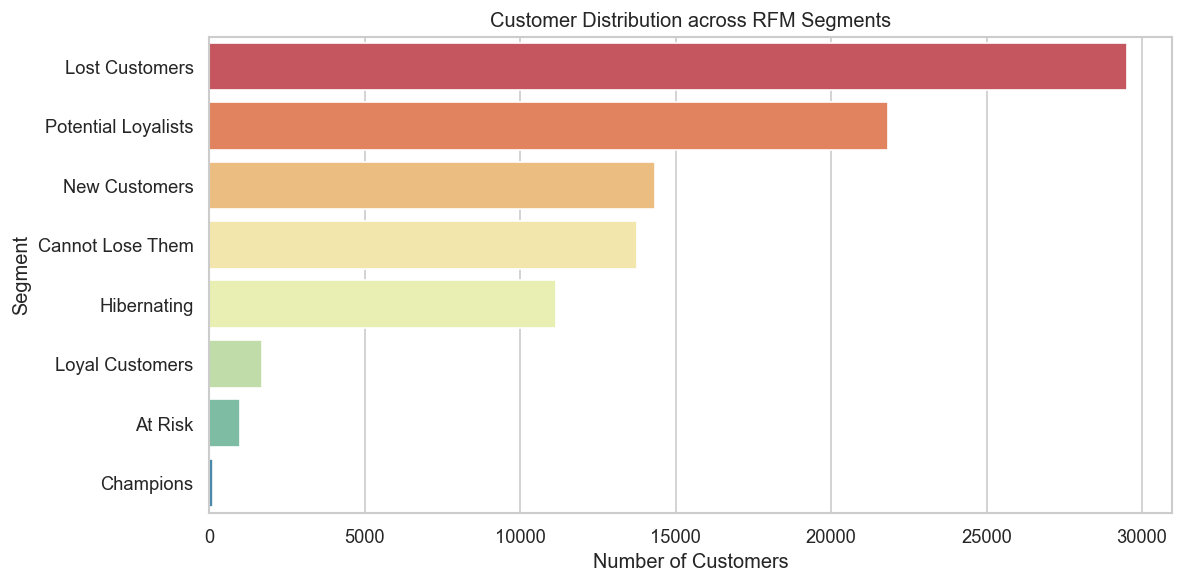

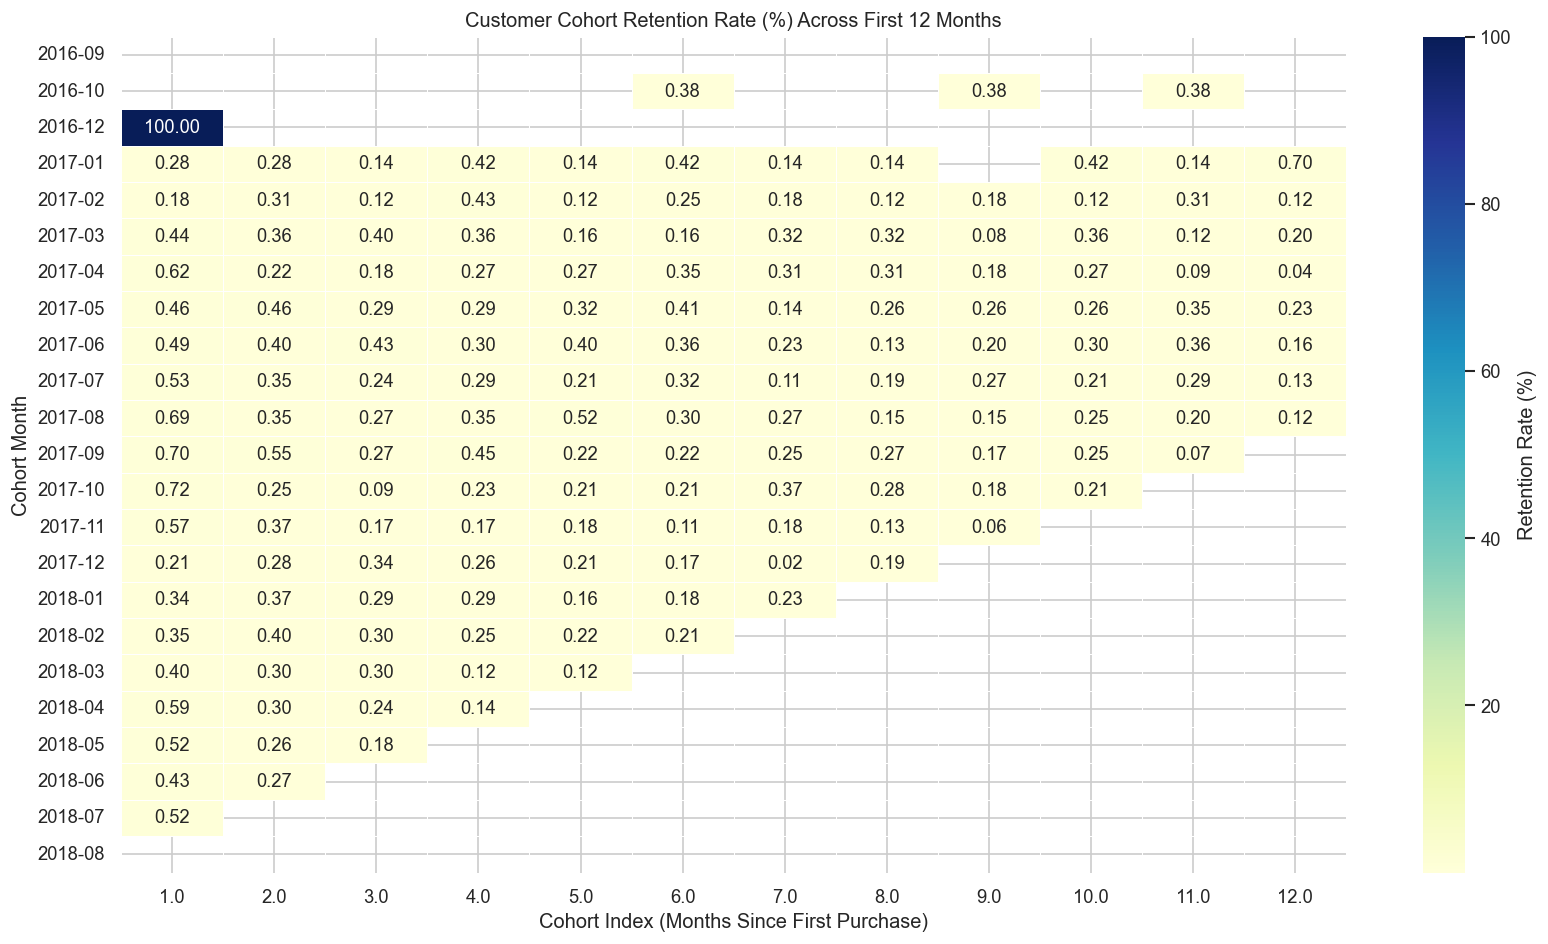

In [14]:
rfm_df = pd.read_csv(data_proc_dir / "mart_customer_rfm.csv")

total_cust = len(rfm_df)
repeat_cust = rfm_df[rfm_df["frequency"] > 1]
repeat_cnt = len(repeat_cust)
repeat_rate = (repeat_cnt / total_cust) * 100

print(f"Total Unique Customers: {total_cust:,}")
print(f"One-Time Customers: {total_cust - repeat_cnt:,} ({100 - repeat_rate:.2f}%)")
print(f"Repeat Customers: {repeat_cnt:,} ({repeat_rate:.2f}%)")
print(f"Total Customer Lifetime Spend: R$ {rfm_df['monetary_value'].sum():,.2f}")
print(f"Repeat Customer Spend Contribution: R$ {repeat_cust['monetary_value'].sum():,.2f} ({repeat_cust['monetary_value'].sum()/rfm_df['monetary_value'].sum()*100:.2f}%)")

# Segment breakdown chart
seg_counts = rfm_df["customer_segment"].value_counts().reset_index()
seg_counts.columns = ["Segment", "Customers"]
seg_counts["Customer %"] = (seg_counts["Customers"] / total_cust) * 100

plt.figure(figsize=(10, 5))
sns.barplot(data=seg_counts, x="Customers", y="Segment", palette="Spectral")
plt.title("Customer Distribution across RFM Segments")
plt.xlabel("Number of Customers")
plt.tight_layout()
plt.savefig(figures_dir / "09_rfm_segments_distribution.png")
plt.show()

# Cohort Heatmap
cohort_df = pd.read_csv(data_proc_dir / "mart_cohort_retention.csv")
cohort_pivot = cohort_df.pivot(index="cohort_label", columns="cohort_index", values="retention_rate_pct")

plt.figure(figsize=(14, 8))
sns.heatmap(cohort_pivot.iloc[:, 1:13], annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Retention Rate (%)'}, linewidths=0.5)
plt.title("Customer Cohort Retention Rate (%) Across First 12 Months")
plt.xlabel("Cohort Index (Months Since First Purchase)")
plt.ylabel("Cohort Month")
plt.tight_layout()
plt.savefig(figures_dir / "10_cohort_retention_heatmap.png")
plt.show()


## Key Business Observations & Takeaways

1. **Extremely Low Baseline Repeat Purchase Rate (3.00%):**
   - 97.00% of unique customers make only a single purchase on the Olist marketplace.
   - Repeat customers account for only 5.60% of total revenue.
   - **Root Cause:** Olist operates as an intermediary infrastructure for third-party sellers selling predominantly durable/one-off items (furniture, appliances, electronics) rather than consumables.
   
2. **Logistics is the Primary Driver of Negative Customer Experience:**
   - 8.11% of delivered orders arrive after the estimated delivery date.
   - When delivered on-time, the average review score is **4.29 stars**.
   - When delayed, the average review score plummets to **2.57 stars** (-1.72 drop), with over 55% leaving 1-star reviews.
   
3. **High Revenue Concentration in Potential Loyalists & Cannot Lose Them:**
   - High-monetary segments ('Potential Loyalists' and 'Cannot Lose Them') drive over **60% of total marketplace revenue**.
   - Proactive post-purchase engagement within the first 60–90 days is essential before customers transition into 'Lost Customers' or 'Hibernating'.
